# Step 5.4: Resolution Degradation

Inference only. The Step 4 checkpoints are reloaded and never modified, and Step 5.0 has confirmed that the reload reproduces the clean baseline.

**The perturbation.** Each spectrum is convolved with a Gaussian of width $\sigma$ pixels:

$$
f_{\text{blurred}}(\lambda_i) = \sum_j f(\lambda_{i-j})\, g_\sigma(j), \qquad
g_\sigma(j) \propto e^{-j^2 / 2\sigma^2}
$$

On the logarithmic grid of Step 2 a fixed pixel width is a fixed *velocity* width at every wavelength, so a single $\sigma$ degrades the resolving power uniformly across the band rather than acting differently at the two ends. This is the same invariance that made a pixel shift a genuine radial-velocity offset in Step 5.3, and it is why the perturbation can be quoted as a single effective resolving power:

$$
R_{\text{eff}} = \frac{c}{\sqrt{\text{FWHM}_{\text{inst}}^2 + (2.355\,\sigma\,\Delta v)^2}}
$$

with $\text{FWHM}_{\text{inst}} = c/2000 \approx 150$ km/s and $\Delta v = 77.0$ km/s per pixel. The grid below runs from $R_{\text{eff}} \approx 1900$ down to about 100, which spans the range from a marginally degraded BOSS spectrum to a survey with essentially no resolved lines. The step therefore answers a practical question alongside the architectural one: **how far can a model trained at $R \approx 2000$ be carried toward a lower-resolution survey before it fails, and which architecture fails first.**

**What the blur is expected to remove.** A Gaussian blur destroys narrow features before broad ones. Temperature is carried by features of very different widths across the sample: metal lines one or two pixels wide in the G and K dwarfs, pressure-broadened Balmer lines tens of pixels wide in the hot stars, and TiO bands hundreds of pixels wide in the coolest ones. The damage is therefore expected to depend strongly on temperature regime, and a difference between the architectures, if one appears, would show where the two models draw on features of different widths. Both are read in Section 5.4.7.

**Why sweep B cannot be assumed to plateau.** Convolution preserves the broadband shape of the continuum exactly, and the naive expectation is that a model would fall back on it, saturating below the collapse ceiling (an RMSE of 962.9 K) with the plateau height decomposing accuracy into a line-borne and a continuum-borne part. That expectation requires the model to degrade gracefully into a regime it has a use for, and there is no reason to assume it does: a spectrum blurred to $\sigma = 64$ px does not resemble anything seen in training, only a smooth curve with the coarse shape of a continuum, and the network's response to an input that far outside its training distribution is an empirical question, not a corollary of what the convolution preserves. Sweep B is run as that empirical test — whether the degradation saturates below the ceiling, approaches it, or exceeds it — rather than as a presumed continuum-only reference. If it does saturate below the ceiling, the plateau height is the information decomposition described above and no other perturbation in this study yields it; if it does not, sweep B is instead a measurement of out-of-distribution behaviour, and is reported as that.

**In the paper.** The degradation against effective resolving power and the paired tests at the thirteen levels of Sweep A (Fig. 3a), the per-regime degradation at $\sigma = 2$ (Fig. 3b), the continuum test of Sweep B and the per-regime bias at $\sigma = 8$. The line-depth diagnostic of Section 5.4.6 and the renormalisation control (Sweep C) are additional and not reported in the paper. Per-spectrum predictions are written to disk, so any configuration can be re-analysed without re-running the attack.

## 5.4.1 Configuration

Three sweeps. Sweep A covers the resolution degradation itself, densely through the onset and sparsely into saturation. Sweep B places two widths far beyond any resolved structure to measure the continuum-only plateau. Sweep C repeats three levels of sweep A without the median renormalisation, to establish that the renormalisation contributes nothing of its own.

A blur has no direction, so each level is a single configuration and there is no directional sweep of the kind Step 5.3 required. The perturbation is deterministic given $\sigma$, so there is no draw-to-draw variance of the kind checked in Step 5.1. As in every previous step, the perturbed tensor is built once at each level and pushed through all ten networks before the next one is generated.

In [1]:
import os
import json
import time
import math

import numpy as np
import pandas as pd
import h5py
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR    = 'data'
RESULTS_DIR = 'results'
CKPT_DIR    = 'checkpoints'
STEP54_DIR  = os.path.join(RESULTS_DIR, 'step54')

MODELS = ['Conv-Pool', 'Conv-Attn']
SEEDS  = [0, 1, 2, 3, 4]

BATCH_SIZE = 256

# ---- attack ------------------------------------------------------------------
ATTACK      = 'resolution_degradation'
ATTACK_SEED = 54          # the blur is deterministic and consumes no random stream

# sweep A: dense through the onset, sparse into saturation
SIGMA_LEVELS     = [0.25, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4, 6, 8, 12, 16]

# sweep B: far beyond any resolved structure — the continuum-only reference
SIGMA_CONTINUUM  = [32, 64]

# sweep C: renormalisation control, a subset of sweep A run without it
SIGMA_NO_RENORM  = [1, 4, 12]

KERNEL_TRUNCATE  = 4.0    # kernel radius in units of sigma
C_KM_S           = 299792.458
R_INSTRUMENT     = 2000.0

CATASTROPHIC_K = 300.0    # same convention as Step 5.0 onward

METRIC_COLS = ['rmse_K', 'mae_K', 'bias_K', 'p99_abs_K', 'gross_fail_frac']

COLORS = {'Conv-Pool': '#0173B2', 'Conv-Attn': '#DE8F05'}

# ==========================================
# PLOT STYLE
# ==========================================
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 130,
})

W_DOUBLE = 7.0

# ==========================================
# LOAD METADATA AND THE STEP 5.0 BASELINE
# ==========================================
import common
device = common.get_device()

os.makedirs(STEP54_DIR, exist_ok=True)

with open(os.path.join(DATA_DIR, 'preprocessing_meta.json')) as f:
    prep = json.load(f)
with open(os.path.join(RESULTS_DIR, 'step50_meta.json')) as f:
    meta50 = json.load(f)

TEFF_MIN    = prep['teff_min']
TEFF_RANGE  = prep['teff_range']
NOISE_FLOOR = meta50['label_noise_floor_K']
GRID        = prep['grid']
GRID_N      = GRID['seq_length']
REG_EDGES   = meta50['regime_edges_K']

assert meta50['gate_passed'], 'Step 5.0 integrity gate did not pass'
assert meta50['eval_batch_size'] == BATCH_SIZE, 'batch size differs from Step 5.0'
assert max(SIGMA_CONTINUUM) * KERNEL_TRUNCATE * 2 < GRID_N, 'kernel wider than the vector'
assert all(s in SIGMA_LEVELS for s in SIGMA_NO_RENORM), \
    'every renormalisation control must have a counterpart in sweep A'

clean_metrics = pd.read_csv(os.path.join(RESULTS_DIR, 'step50_baseline_metrics.csv'))

n_cfg = len(SIGMA_LEVELS) + len(SIGMA_CONTINUUM) + len(SIGMA_NO_RENORM)
print(f'Device  : {device}')
print(f'Sweep A : sigma in {SIGMA_LEVELS} px, median-renormalised')
print(f'Sweep B : sigma in {SIGMA_CONTINUUM} px, continuum-only reference')
print(f'Sweep C : sigma in {SIGMA_NO_RENORM} px, renormalisation withheld')
print(f'{n_cfg} configurations, {n_cfg * len(SEEDS) * len(MODELS)} forward passes')

Device  : cpu
Sweep A : sigma in [0.25, 0.5, 0.75, 1, 1.5, 2, 2.5, 3, 4, 6, 8, 12, 16] px, median-renormalised
Sweep B : sigma in [32, 64] px, continuum-only reference
Sweep C : sigma in [1, 4, 12] px, renormalisation withheld
18 configurations, 180 forward passes


## 5.4.2 Architectures

The two models are defined once, in `models.py`, and loaded through `common.py` exactly as in Step 5.0. The parity check halts the notebook if a definition has drifted from the one the checkpoints were written against.

In [2]:
from models import SharedStem, check_parameter_parity
import common

check_parameter_parity()


def load_model(model_name, seed):
    return common.load_model(model_name, seed, device, CKPT_DIR)


def predict(model, x, batch_size=BATCH_SIZE):
    """Forward a device-resident tensor; returns absolute temperatures in Kelvin."""
    return common.predict(model, x, TEFF_MIN, TEFF_RANGE, batch_size)


def metrics(pred_k, true_k):
    return common.metrics(pred_k, true_k, CATASTROPHIC_K)


Conv-Pool : 537,857 parameters
Conv-Attn : 540,161 parameters
difference: 2,304 (0.43%)


## 5.4.3 Test partition, grid, and the two reference levels

Loaded exactly as in Step 4a and every Step 5 notebook. Two reference values are computed here and carried through the analysis.

The **collapse ceiling** is the RMSE of the best constant predictor, the value a model reaches when the input carries no usable information at all. A blur is not expected to reach it, and the distance between the observed plateau and this ceiling is the point.

The **effective resolving power** converts each $\sigma$ into the quantity a spectroscopist would quote, so that the sweep can be read against real survey configurations rather than against pixel counts.

In [3]:
test_idx, X_test, y_true_k = common.load_test_split(DATA_DIR, GRID_N)
N_TEST = len(test_idx)
X_clean = torch.from_numpy(X_test).to(device)

regime = pd.cut(y_true_k, bins=REG_EDGES)
REG_LABELS = [str(c) for c in regime.categories]
regime_mask = {str(c): np.asarray(regime == c) for c in regime.categories}

assert not np.isnan(X_test).any(), 'NaN in the test tensor'

# --- reference values ---------------------------------------------------------
COLLAPSE_RMSE = float(np.std(y_true_k))
CEILING = {m: COLLAPSE_RMSE - float(
    clean_metrics[(clean_metrics.model == m) &
                  (clean_metrics.regime == 'all')]['rmse_K'].mean())
    for m in MODELS}
CEILING_MEAN = float(np.mean(list(CEILING.values())))
CLEAN_RMSE = {m: float(clean_metrics[(clean_metrics.model == m) &
                                     (clean_metrics.regime == 'all')]['rmse_K'].mean())
              for m in MODELS}

# --- wavelength grid ----------------------------------------------------------
GRID_LO, GRID_HI = GRID['wave_start'], GRID['wave_end']
KMS_PER_PIXEL = GRID['km_s_per_pixel']
wavegrid = GRID_LO * (GRID_HI / GRID_LO) ** (np.arange(GRID_N) / (GRID_N - 1))
pixel_axis = np.arange(GRID_N)

FWHM_INSTRUMENT = C_KM_S / R_INSTRUMENT


def r_effective(sigma):
    """Resolving power after convolving the instrumental profile with the blur."""
    fwhm_blur = 2.3548 * sigma * KMS_PER_PIXEL
    return C_KM_S / math.sqrt(FWHM_INSTRUMENT ** 2 + fwhm_blur ** 2)


def lam_to_pixel(lam):
    return float(np.interp(lam, wavegrid, pixel_axis))


LINES = {'Ca II K': 3933.7, 'H-delta': 4101.7, 'H-gamma': 4340.5, 'H-beta': 4861.3,
         'Mg b': 5175.0, 'Na D': 5893.0, 'H-alpha': 6562.8, 'TiO bandhead': 7055.0,
         'Ca II 8542': 8542.1}

print(f'test spectra   : {N_TEST:,}')
print(f'grid           : {GRID_LO:.0f}-{GRID_HI:.0f} A, {GRID_N} points, '
      f'{KMS_PER_PIXEL:.2f} km/s per pixel')
print(f'collapse RMSE  : {COLLAPSE_RMSE:.1f} K (best constant predictor)')
print(f'ceiling on dRMSE: ' + ', '.join(f'{m} {CEILING[m]:.1f} K' for m in MODELS))
print()
print('sweep A levels in physical units:')
print(f'  {"sigma (px)":>11} {"FWHM (km/s)":>12} {"R_eff":>8}   comparable to')
_ref = [(1900, 'BOSS as observed'), (1500, ''), (1000, ''), (700, ''),
        (400, 'a low-resolution survey'), (200, ''), (100, 'no resolved lines')]
for s in SIGMA_LEVELS:
    r = r_effective(s)
    tag = ''
    for rv, lab in _ref:
        if lab and abs(r - rv) / rv < 0.18:
            tag = lab
    print(f'  {s:>11.2f} {2.3548 * s * KMS_PER_PIXEL:>12.0f} {r:>8.0f}   {tag}')
print()
print('sweep B levels, the continuum-only reference:')
for s in SIGMA_CONTINUUM:
    print(f'  {s:>11.2f} {2.3548 * s * KMS_PER_PIXEL:>12.0f} {r_effective(s):>8.0f}')
del _ref

test spectra   : 18,898
grid           : 3600-10300 A, 4096 points, 76.96 km/s per pixel
collapse RMSE  : 962.9 K (best constant predictor)
ceiling on dRMSE: Conv-Pool 881.9 K, Conv-Attn 881.2 K

sweep A levels in physical units:
   sigma (px)  FWHM (km/s)    R_eff   comparable to
         0.25           45     1914   BOSS as observed
         0.50           91     1712   BOSS as observed
         0.75          136     1482   
         1.00          181     1275   
         1.50          272      966   
         2.00          362      764   
         2.50          453      628   
         3.00          544      532   
         4.00          725      405   a low-resolution survey
         6.00         1087      273   
         8.00         1450      206   
        12.00         2175      138   
        16.00         2900      103   no resolved lines

sweep B levels, the continuum-only reference:
        32.00         5799       52
        64.00        11598       26


## 5.4.4 The perturbation

A Gaussian kernel truncated at four standard deviations, normalised to unit sum so that the continuum level is preserved, applied with replicated edge padding. The padding convention matches Step 2, which extends the first usable value across the 59 unusable pixels at the blue edge, and Step 5.3, which used the same rule for the vacated edge of a shift.

**Renormalisation.** Step 2 divides each spectrum by the median of its positive pixels. A spectrum recorded by a lower-resolution spectrograph would pass through that same step, so the pipeline-faithful operation is to renormalise after blurring, and sweep A does. Because the renormalisation is a second operation whose effect is not obviously negligible, sweep C repeats three levels with it withheld.

**What a convolution does and does not destroy.** It conserves the integral, so the equivalent width of every line survives exactly; what it removes is line *depth* and the distinction between narrow and broad features. It also leaves the broadband continuum shape untouched, which is why one might expect the degradation to saturate below the collapse ceiling; Sweep B tests that expectation rather than assuming it. The verification below checks both properties directly, along with the width semantics: convolving a Gaussian line of width $w$ must give a line of width $\sqrt{w^2 + \sigma^2}$, which is what fixes the meaning of $\sigma$ in the table above.

In [4]:
def gaussian_kernel(sigma, truncate=KERNEL_TRUNCATE):
    r = int(math.ceil(truncate * sigma))
    x = torch.arange(-r, r + 1, dtype=torch.float32, device=device)
    k = torch.exp(-0.5 * (x / sigma) ** 2)
    return k / k.sum()


def renormalise(x):
    """Divide by the median of the positive pixels, as Step 2 does."""
    tmp = x.clone()
    tmp[tmp <= 0] = float('nan')
    med = tmp.nanmedian(dim=-1, keepdim=True).values
    med = torch.nan_to_num(med, nan=1.0)
    med = torch.where(med.abs() < 1e-8, torch.ones_like(med), med)
    return x / med


def blur(x, sigma, renorm=True, chunk=2048):
    """Convolve with a Gaussian of width sigma pixels, replicated edges.

    sigma <= 0 returns a copy. x is left untouched."""
    if sigma <= 0:
        return x.clone()
    k = gaussian_kernel(sigma).view(1, 1, -1)
    r = (k.shape[-1] - 1) // 2
    outs = []
    for i in range(0, x.shape[0], chunk):
        xb = F.pad(x[i:i + chunk], (r, r), mode='replicate')
        ob = F.conv1d(xb, k)
        if renorm:
            ob = renormalise(ob)
        outs.append(ob)
        del xb, ob
    return torch.cat(outs, dim=0)


def run_tensor(x_att):
    """Evaluate all ten networks on one perturbed tensor."""
    out = np.empty((len(SEEDS), len(MODELS), N_TEST), dtype=np.float32)
    for si, seed in enumerate(SEEDS):
        for mi, m in enumerate(MODELS):
            model = load_model(m, seed)
            out[si, mi] = predict(model, x_att).astype(np.float32)
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    return out


def path_sigma(sigma, renorm=True):
    whole, frac = int(sigma), int(round((sigma - int(sigma)) * 100))
    tag = '' if renorm else '_raw'
    return os.path.join(STEP54_DIR, f'preds_sig{whole:03d}p{frac:02d}{tag}.npz')


PATH_CLEAN = os.path.join(STEP54_DIR, 'preds_clean.npz')

# --- verification -------------------------------------------------------------
_t = torch.arange(GRID_N, dtype=torch.float32, device=device)

# kernels are normalised
for _s in [0.25, 1.0, 4.0, 16.0, 64.0]:
    _k = gaussian_kernel(_s)
    assert abs(float(_k.sum()) - 1.0) < 1e-6, f'kernel does not sum to one at {_s}'

# a constant survives untouched, edges included
_const = torch.full((2, 1, GRID_N), 1.37, device=device)
for _s in [0.5, 4.0, 32.0]:
    _o = blur(_const, _s, renorm=False)
    assert torch.allclose(_o, _const, atol=1e-4), f'a constant is not preserved at {_s}'

# the integral is conserved in the interior: equivalent width survives
_line = 1.0 - 0.6 * torch.exp(-0.5 * ((_t - 2000.0) / 2.0) ** 2)
_line = _line.reshape(1, 1, GRID_N)
for _s in [1.0, 4.0]:
    _o = blur(_line, _s, renorm=False)
    _ew_c = float((1.0 - _line[:, :, 1800:2200]).sum())
    _ew_b = float((1.0 - _o[:, :, 1800:2200]).sum())
    assert abs(_ew_b / _ew_c - 1.0) < 0.01, f'equivalent width not conserved at {_s}'

# sigma semantics: a Gaussian of width w becomes one of width sqrt(w^2 + s^2)
def fwhm_sigma(prof):
    """Gaussian width from the half-maximum points with the flanks interpolated.

    The flanks must be interpolated: counting samples
    above half maximum quantises the estimate and biases it low by about a pixel,
    which is the whole width of the narrowest features here."""
    prof = prof - prof.min()
    m = float(prof.max())
    if m <= 0:
        return float('nan')
    i0 = int(prof.argmax())
    half = m / 2.0
    l = i0
    while l > 0 and float(prof[l]) > half:
        l -= 1
    xl = (l + (half - float(prof[l])) / (float(prof[l + 1]) - float(prof[l]))
          if float(prof[l + 1]) != float(prof[l]) else float(l))
    r = i0
    while r < len(prof) - 1 and float(prof[r]) > half:
        r += 1
    xr = (r - (half - float(prof[r])) / (float(prof[r - 1]) - float(prof[r]))
          if float(prof[r - 1]) != float(prof[r]) else float(r))
    return (xr - xl) / 2.3548


def _fit_width(y):
    return fwhm_sigma((1.0 - y).flatten())


_w0 = 2.0
print('sigma semantics, a Gaussian line of width 2.0 px convolved with the kernel:')
for _s in [1.0, 2.0, 4.0]:
    _o = blur(_line, _s, renorm=False)
    _got, _exp = _fit_width(_o), math.sqrt(_w0 ** 2 + _s ** 2)
    print(f'  sigma = {_s:4.1f}: measured width {_got:5.2f} px, expected {_exp:5.2f} px')
    assert abs(_got - _exp) / _exp < 0.10, f'width semantics wrong at {_s}'

assert torch.equal(blur(_const, 0.0, renorm=False), _const), 'sigma = 0 is not a no-op'

# --- discretisation floor -------------------------------------------------
# A Gaussian kernel sampled on the integer pixel grid cannot deliver a width
# narrower than roughly half a pixel: below that the kernel degenerates toward
# a delta function regardless of the nominal sigma. Measured directly as the
# realised second moment of the sampled-and-truncated kernel.
def _kernel_realised_sigma(sigma):
    k = gaussian_kernel(sigma).cpu()
    r = (len(k) - 1) // 2
    x = torch.arange(-r, r + 1, dtype=torch.float64)
    return float((k.double() * x ** 2).sum().sqrt())

print()
print('discretisation floor of the sampled kernel:')
DISCRETISATION_FLOOR_PX = None
for _s in [0.25, 0.5, 0.75, 1.0]:
    _real = _kernel_realised_sigma(_s)
    _err = 100 * (_real - _s) / _s
    print(f'  nominal sigma = {_s:.2f} px -> realised {_real:.4f} px  ({_err:+.1f}%)')
    if abs(_err) > 15 and DISCRETISATION_FLOOR_PX is None:
        DISCRETISATION_FLOOR_PX = _s
if DISCRETISATION_FLOOR_PX is not None:
    print(f'  levels at or below {DISCRETISATION_FLOOR_PX:.2f} px do not deliver their')
    print(f'  nominal width and should be read as the near-zero control, not as a')
    print(f'  measurement of blurring at that specific width')
del _real, _err

print()
print('verified: kernels normalised, a constant and the continuum survive, equivalent')
print('width is conserved, and the width of a blurred line follows the quadrature rule')
del _t, _const, _line, _o, _k, _s, _w0, _got, _exp, _ew_c, _ew_b

sigma semantics, a Gaussian line of width 2.0 px convolved with the kernel:
  sigma =  1.0: measured width  2.25 px, expected  2.24 px
  sigma =  2.0: measured width  2.84 px, expected  2.83 px
  sigma =  4.0: measured width  4.48 px, expected  4.47 px

discretisation floor of the sampled kernel:
  nominal sigma = 0.25 px -> realised 0.0259 px  (-89.6%)
  nominal sigma = 0.50 px -> realised 0.4637 px  (-7.3%)
  nominal sigma = 0.75 px -> realised 0.7497 px  (-0.0%)
  nominal sigma = 1.00 px -> realised 1.0000 px  (-0.0%)
  levels at or below 0.25 px do not deliver their
  nominal width and should be read as the near-zero control, not as a
  measurement of blurring at that specific width

verified: kernels normalised, a constant and the continuum survive, equivalent
width is conserved, and the width of a blurred line follows the quadrature rule


## 5.4.5 Sweeps

All three run on the full test partition. Results are written per level, so an interrupted run resumes rather than restarting. The clean predictions are cached alongside them, since the analysis of the plateau needs per-spectrum clean values rather than only their summary.

In [5]:
_m = load_model(MODELS[0], SEEDS[0])
_t0 = time.time(); predict(_m, X_clean); _t = time.time() - _t0
del _m
if device.type == 'cuda':
    torch.cuda.empty_cache()

todo = sum(1 for s in SIGMA_LEVELS + SIGMA_CONTINUUM
           if not os.path.exists(path_sigma(s)))
todo += sum(1 for s in SIGMA_NO_RENORM if not os.path.exists(path_sigma(s, False)))
todo += 0 if os.path.exists(PATH_CLEAN) else 1

print(f'one forward pass : {_t:.1f} s')
print(f'tensors to run   : {todo}  ({todo * len(SEEDS) * len(MODELS)} forward passes)')
print(f'projected total  : {_t * todo * len(SEEDS) * len(MODELS) * 1.4 / 60:.0f} min')
print('Configurations already on disk are skipped.')

one forward pass : 12.0 s
tensors to run   : 19  (190 forward passes)
projected total  : 53 min
Configurations already on disk are skipped.


In [6]:
if os.path.exists(PATH_CLEAN):
    print('[skip] clean predictions')
else:
    t0 = time.time()
    preds = run_tensor(X_clean)
    np.savez_compressed(PATH_CLEAN, preds=preds, seeds=np.array(SEEDS),
                        models=np.array(MODELS))
    rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
    print('clean              ' + '   '.join(
        f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
        + f'   ({time.time() - t0:.0f}s)')


def run_sigma_levels(levels, label, renorm=True):
    for s in levels:
        p = path_sigma(s, renorm)
        if os.path.exists(p):
            print(f'[skip] {label} sigma = {s:6.2f}' + ('' if renorm else '  (raw)'))
            continue
        t0 = time.time()
        X_att = blur(X_clean, s, renorm=renorm)
        preds = run_tensor(X_att)
        del X_att
        np.savez_compressed(p, preds=preds, sigma=float(s), sweep=label,
                            renormalised=bool(renorm), r_eff=r_effective(s),
                            seeds=np.array(SEEDS), models=np.array(MODELS),
                            attack_seed=ATTACK_SEED)
        rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
        print(f'{label} sigma = {s:6.2f}  R_eff {r_effective(s):5.0f}   ' + '   '.join(
            f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
            + f'   ({time.time() - t0:.0f}s)')


run_sigma_levels(SIGMA_LEVELS, 'A')

clean              Conv-Pool   81.07 K   Conv-Attn   81.72 K   (162s)
A sigma =   0.25  R_eff  1914   Conv-Pool   81.07 K   Conv-Attn   81.72 K   (184s)
A sigma =   0.50  R_eff  1712   Conv-Pool   81.05 K   Conv-Attn   81.97 K   (182s)
A sigma =   0.75  R_eff  1482   Conv-Pool   86.67 K   Conv-Attn   87.35 K   (194s)
A sigma =   1.00  R_eff  1275   Conv-Pool  101.35 K   Conv-Attn  100.19 K   (195s)
A sigma =   1.50  R_eff   966   Conv-Pool  161.66 K   Conv-Attn  152.75 K   (196s)
A sigma =   2.00  R_eff   764   Conv-Pool  236.85 K   Conv-Attn  215.39 K   (195s)
A sigma =   2.50  R_eff   628   Conv-Pool  300.43 K   Conv-Attn  270.29 K   (195s)
A sigma =   3.00  R_eff   532   Conv-Pool  349.43 K   Conv-Attn  320.56 K   (197s)
A sigma =   4.00  R_eff   405   Conv-Pool  441.30 K   Conv-Attn  432.26 K   (194s)
A sigma =   6.00  R_eff   273   Conv-Pool  607.32 K   Conv-Attn  572.89 K   (193s)
A sigma =   8.00  R_eff   206   Conv-Pool  678.40 K   Conv-Attn  581.72 K   (201s)
A sigma =  12.00 

In [7]:
run_sigma_levels(SIGMA_CONTINUUM, 'B')

B sigma =  32.00  R_eff    52   Conv-Pool  861.69 K   Conv-Attn  933.95 K   (215s)
B sigma =  64.00  R_eff    26   Conv-Pool  977.44 K   Conv-Attn 1011.97 K   (218s)


In [8]:
run_sigma_levels(SIGMA_NO_RENORM, 'C', renorm=False)

C sigma =   1.00  R_eff  1275   Conv-Pool  101.35 K   Conv-Attn  100.20 K   (213s)
C sigma =   4.00  R_eff   405   Conv-Pool  441.34 K   Conv-Attn  432.40 K   (206s)
C sigma =  12.00  R_eff   138   Conv-Pool  780.34 K   Conv-Attn  685.86 K   (203s)


## 5.4.6 What the blur does to each diagnostic line

A data-side diagnostic that costs no forward pass, additional to the paper. It measures the rate at which each diagnostic line loses its depth under blur, the quantity behind the regime structure expected in the introduction.

**The measurement window must be sized to the feature, not fixed.** A narrow metal line and a molecular band spanning hundreds of pixels cannot share one continuum window: a window comparable to or narrower than the band sits entirely inside it, so the local continuum estimate is dragged down by the very feature being measured and can report a depth-retained ratio above one, which is not physically possible for a convolution. Each line below is therefore measured with a continuum window at least four times its own expected width.

**The profile must be measured per temperature regime, not pooled.** Several of these features change intrinsic width with temperature — the Balmer series broadens in hot stars through the linear Stark effect and is comparatively narrow in the G and K dwarfs that dominate the sample by number. A width measured on the pooled sample is therefore biased toward the core seen in the majority population, not the width relevant to the stars where the line is diagnostic. The profile is measured separately in three broad regimes and the narrowest of the three is kept as the operative width, since that is the regime in which the blur removes the feature first.

In [9]:
EXPECTED_WIDTH_PX = {                    # rough prior used only to size the window
    'Ca II K': 5, 'H-delta': 6, 'H-gamma': 6, 'H-beta': 6, 'Mg b': 4,
    'Na D': 4, 'H-alpha': 8, 'TiO bandhead': 250, 'Ca II 8542': 5,
}                                                                # elsewhere in the fit
WINDOW_FACTOR = 6         # continuum window = this many times the expected width
MIN_WINDOW = 60

REGIME_BANDS = {'cool (<5000K)': (3500, 5000),
                'mid (5000-6500K)': (5000, 6500),
                'hot (>6500K)': (6500, 9000)}
regime_sel = {lab: np.asarray((y_true_k >= lo) & (y_true_k < hi))
             for lab, (lo, hi) in REGIME_BANDS.items()}

_sub = X_clean[:4000]
_sub_y = y_true_k[:4000]
_sub_regime = {lab: np.asarray((_sub_y >= lo) & (_sub_y < hi))
              for lab, (lo, hi) in REGIME_BANDS.items()}


def profile_width(prof):
    """FWHM in pixels from a 1-D profile, flanks linearly interpolated so the
    estimate is not quantised to the pixel grid."""
    prof = prof - prof.min()
    m = float(prof.max())
    if m <= 0:
        return float('nan')
    i0 = int(prof.argmax())
    half = m / 2.0
    l = i0
    while l > 0 and float(prof[l]) > half:
        l -= 1
    xl = (l + (half - float(prof[l])) / (float(prof[l + 1]) - float(prof[l]))
          if float(prof[l + 1]) != float(prof[l]) else float(l))
    r = i0
    while r < len(prof) - 1 and float(prof[r]) > half:
        r += 1
    xr = (r - (half - float(prof[r])) / (float(prof[r - 1]) - float(prof[r]))
          if float(prof[r - 1]) != float(prof[r]) else float(r))
    return (xr - xl) / 2.3548


rows = []
width_rows = []
for name, lam in LINES.items():
    p = int(round(lam_to_pixel(lam)))
    half_win = max(MIN_WINDOW, WINDOW_FACTOR * EXPECTED_WIDTH_PX.get(name, 10))
    if p - half_win < 0 or p + half_win >= GRID_N:
        half_win = min(p, GRID_N - 1 - p)
    if half_win < 10:
        continue

    # width per regime, on the full clean tensor restricted to that regime
    regime_widths = {}
    for lab, sel in regime_sel.items():
        if sel.sum() < 200:
            continue
        idx = np.nonzero(sel)[0][:3000]
        win = X_clean[idx, 0, p - half_win:p + half_win + 1]
        cont = win.median(dim=-1, keepdim=True).values
        prof = (cont - win).mean(dim=0)
        # a regime where the feature has negligible depth (a molecular band
        # absent in hot stars, say) gives a width fitted to noise rather than
        # to the feature; require the peak to be a non-trivial fraction of the
        # local continuum before the width in that regime is trusted
        peak_depth = float(prof.max())
        local_cont = float(cont.mean())
        if local_cont <= 0 or peak_depth / local_cont < 0.01:
            del win, cont, prof
            continue
        w = profile_width(prof)
        regime_widths[lab] = w
        width_rows.append({'line': name, 'regime': lab, 'window_px': half_win,
                           'width_px': w, 'peak_depth_frac': peak_depth / local_cont})
        del win, cont, prof

    finite = [w for w in regime_widths.values() if w == w and w > 0]
    op_width = min(finite) if finite else float('nan')

    # restrict the depth-retained measurement to spectra where the feature is
    # actually present, by the same significance gate as the width fit above;
    # pooling in spectra without the feature would dilute the measured depth
    # with noise and bias the retained fraction
    win_all = X_clean[:, 0, p - half_win:p + half_win + 1]
    cont_all = win_all.median(dim=-1, keepdim=True).values.squeeze(-1)
    depth_all = cont_all - X_clean[:, 0, p]
    present = (depth_all > 0.01 * cont_all.clamp(min=1e-6))
    idx_present = torch.nonzero(present).flatten()[:2000]
    if len(idx_present) < 50:
        idx_present = torch.arange(min(2000, N_TEST))
    del win_all, cont_all, depth_all, present

    win_c = X_clean[idx_present, 0, p - half_win:p + half_win + 1]
    cont_c = win_c.median(dim=-1, keepdim=True).values
    depth_c = (cont_c.squeeze(-1) - X_clean[idx_present, 0, p])
    for s in SIGMA_LEVELS:
        ob = blur(X_clean[idx_present], s, renorm=True)
        win_b = ob[:, 0, p - half_win:p + half_win + 1]
        cont_b = win_b.median(dim=-1, keepdim=True).values
        depth_b = (cont_b.squeeze(-1) - ob[:, 0, p])
        # a small overshoot above 1.0 is expected noise variance when the
        # feature depth is comparable to the pixel-level noise, not a sign
        # the window is mis-sized -- verified separately on noise-free
        # synthetic lines, where the same measurement never exceeds 1.0
        keep = float((depth_b.mean() / depth_c.mean()).clamp(min=0, max=1.5))
        rows.append({'line': name, 'lambda_A': lam, 'pixel': p,
                     'window_px': half_win, 'operative_width_px': op_width,
                     'sigma': s, 'depth_retained': keep,
                     'n_present': int(len(idx_present))})
        del ob, win_b, cont_b, depth_b

lineprof = pd.DataFrame(rows)
linewidths = pd.DataFrame(width_rows)
lineprof.to_csv(os.path.join(RESULTS_DIR, 'step54_line_morphology.csv'), index=False)
linewidths.to_csv(os.path.join(RESULTS_DIR, 'step54_line_widths_by_regime.csv'),
                  index=False)

print('Intrinsic width by temperature regime (px), narrowest of the three kept as '

      'the operative width:')
wt = linewidths.pivot_table(index='line', columns='regime', values='width_px')
cols = [c for c in ['cool (<5000K)', 'mid (5000-6500K)', 'hot (>6500K)'] if c in wt.columns]
op = lineprof.groupby('line')['operative_width_px'].first()
wt['operative'] = op
print(wt[cols + ['operative']].round(2).sort_values('operative').to_string())
print()
print('A window at least six times the operative width, and at least 60 pixels, avoids '

      'the continuum estimate sitting inside the feature it is measuring — the failure '

      'mode of a fixed narrow window on a broad band, which returns a depth-retained '

      'ratio above one and is the reason this diagnostic was rebuilt.')
print()
widths_sorted = op.sort_values()
print('Fraction of line depth retained after blurring, ordered by operative width:')
tab = lineprof.pivot_table(index='line', columns='sigma', values='depth_retained')
print(tab.reindex(widths_sorted.index)[[0.5, 1, 2, 4, 8]].round(3).to_string())
print()
print('A feature is expected to lose half its depth near sigma equal to its own '

      'operative width, so the row order above is the order in which the blur removes '

      'the information each body could in principle depend on.')
del _sub, _sub_y, _sub_regime

Intrinsic width by temperature regime (px), narrowest of the three kept as the operative width:
regime        cool (<5000K)  mid (5000-6500K)  hot (>6500K)  operative
line                                                                  
Ca II 8542             1.74              1.65          1.76       1.65
Mg b                   7.46              1.76          2.85       1.76
H-beta                 1.87              2.28          4.20       1.87
H-alpha                2.08              1.89          2.66       1.89
H-delta                2.40              2.60          5.42       2.40
H-gamma               12.83              2.47          4.32       2.47
Na D                   3.57              3.23          3.27       3.23
TiO bandhead          43.56           1049.17          4.20       4.20
Ca II K               13.56              4.53          4.35       4.35

A window at least six times the operative width, and at least 60 pixels, avoids the continuum estimate sitting inside the 

## 5.4.7 Degradation

Every quantity is a difference against the Step 5.0 clean value, taken **within the same model and seed**, exactly as in Steps 5.1 to 5.3.

In [10]:
def degradation_from(paths):
    """paths: list of (level_dict, filepath)."""
    rows = []
    for level, p in paths:
        preds = np.load(p)['preds']
        for si, seed in enumerate(SEEDS):
            for mi, m in enumerate(MODELS):
                pr = preds[si, mi].astype(np.float64)
                rows.append({**level, 'model': m, 'seed': seed, 'regime': 'all',
                             **metrics(pr, y_true_k)})
                for lab, sel in regime_mask.items():
                    rows.append({**level, 'model': m, 'seed': seed, 'regime': lab,
                                 **metrics(pr[sel], y_true_k[sel])})
    att = pd.DataFrame(rows)
    deg = att.merge(clean_metrics[['model', 'seed', 'regime'] + METRIC_COLS],
                    on=['model', 'seed', 'regime'], suffixes=('', '_clean'))
    for c in METRIC_COLS:
        deg['d_' + c] = deg[c] - deg[c + '_clean']
    return deg


paths = []
for s in SIGMA_LEVELS:
    paths.append(({'sweep': 'A', 'sigma': float(s), 'renormalised': True,
                   'r_eff': r_effective(s)}, path_sigma(s)))
for s in SIGMA_CONTINUUM:
    paths.append(({'sweep': 'B', 'sigma': float(s), 'renormalised': True,
                   'r_eff': r_effective(s)}, path_sigma(s)))
paths_c = []
for s in SIGMA_NO_RENORM:
    paths_c.append(({'sweep': 'C', 'sigma': float(s), 'renormalised': False,
                     'r_eff': r_effective(s)}, path_sigma(s, False)))

deg = degradation_from(paths)
deg_c = degradation_from(paths_c)
deg.to_csv(os.path.join(RESULTS_DIR, 'step54_degradation.csv'), index=False)
deg_c.to_csv(os.path.join(RESULTS_DIR, 'step54_degradation_norenorm.csv'), index=False)

ov = deg[deg.regime == 'all']
ov_A = ov[ov.sweep == 'A']
ov_B = ov[ov.sweep == 'B']
ov_c = deg_c[deg_c.regime == 'all']
print(f'{len(deg):,} rows for sweeps A and B, {len(deg_c):,} for the renormalisation '
      f'control')

1,500 rows for sweeps A and B, 300 for the renormalisation control


In [11]:
piv = ov_A.pivot_table(index='sigma', columns='model', values='d_rmse_K',
                       aggfunc=['mean', 'std'])
piv.insert(0, 'R_eff', [round(r_effective(s)) for s in sorted(ov_A.sigma.unique())])
print('Sweep A — overall RMSE degradation (K), mean and SD over seeds:')
print(piv.round(2).to_string())
print()
print('Collapse ceiling on this quantity: ' +
      ', '.join(f'{m} {CEILING[m]:.0f} K' for m in MODELS))
print('A blur preserves the continuum, so the curve is expected to saturate below it')
print('rather than approach it.')

Sweep A — overall RMSE degradation (K), mean and SD over seeds:
      R_eff      mean                 std          
model       Conv-Attn Conv-Pool Conv-Attn Conv-Pool
sigma                                              
0.25   1914     -0.00     -0.00      0.00      0.00
0.50   1712      0.24     -0.02      0.41      0.66
0.75   1482      5.62      5.60      1.11      2.06
1.00   1275     18.46     20.28      2.80      4.69
1.50    966     71.02     80.59     11.03     12.26
2.00    764    133.66    155.78     16.27     17.92
2.50    628    188.56    219.35     22.86     25.20
3.00    532    238.83    268.35     49.23     35.60
4.00    405    350.54    360.23     97.87     49.17
6.00    273    491.16    526.25    120.29     70.93
8.00    206    500.00    597.33     81.61     65.89
12.00   138    604.01    700.01     66.33     71.60
16.00   103    694.41    772.48     82.70    105.80

Collapse ceiling on this quantity: Conv-Pool 882 K, Conv-Attn 881 K
A blur preserves the continuum, so 

In [12]:
tests = []
for s in sorted(ov[ov.sweep.isin(['A', 'B'])].sigma.unique()):
    sub = ov[ov.sigma == s]
    a = sub[sub.model == 'Conv-Pool'].sort_values('seed')['d_rmse_K'].values
    c = sub[sub.model == 'Conv-Attn'].sort_values('seed')['d_rmse_K'].values
    diff = c - a
    sd = float(diff.std(ddof=1))
    t, p = stats.ttest_rel(c, a)
    tests.append({'sigma': s, 'r_eff': round(r_effective(s)),
                  'gap_K': float(diff.mean()), 'sd_of_diff': sd,
                  'gap_over_sd': float(diff.mean() / sd) if sd > 0 else np.nan,
                  'p_paired_t': float(p)})
tests = pd.DataFrame(tests)
tests.to_csv(os.path.join(RESULTS_DIR, 'step54_paired_tests.csv'), index=False)
print(tests.round(4).to_string(index=False))
print()
print('The gap is Conv-Attn minus Conv-Pool, so a negative value means Conv-Attn degrades')
print('less, matching the convention of Steps 5.2 and 5.3. A gap-to-scatter ratio well')
print('below 2 at every level, with p < 0.05 at no more levels than chance would give,')
print('means that no architectural gap is resolved under blur.')

 sigma  r_eff    gap_K  sd_of_diff  gap_over_sd  p_paired_t
  0.25   1914   0.0008      0.0028       0.2983      0.5413
  0.50   1712   0.2639      0.6759       0.3905      0.4318
  0.75   1482   0.0222      1.7189       0.0129      0.9783
  1.00   1275  -1.8142      4.2585      -0.4260      0.3947
  1.50    966  -9.5633     13.8403      -0.6910      0.1972
  2.00    764 -22.1213     17.4387      -1.2685      0.0470
  2.50    628 -30.7889     30.4869      -1.0099      0.0869
  3.00    532 -29.5206     66.7033      -0.4426      0.3784
  4.00    405  -9.6916    124.8042      -0.0777      0.8706
  6.00    273 -35.0875    137.1696      -0.2558      0.5979
  8.00    206 -97.3317    100.5751      -0.9678      0.0965
 12.00    138 -96.0076     78.2280      -1.2273      0.0517
 16.00    103 -78.0713     76.4440      -1.0213      0.0844
 32.00     52  71.6091    113.5400       0.6307      0.2313
 64.00     26  33.8842    169.0040       0.2005      0.6771

The gap is Conv-Attn minus Conv-Pool, s

### The plateau, and what it says about the information sources

If the degradation saturates, the plateau is the accuracy a model retains when every resolved line has been removed and only the continuum shape remains. Comparing it with the clean RMSE decomposes the model's accuracy into a part carried by lines and a part carried by the continuum — a quantity no other perturbation in this study provides.

In [13]:
plateau = []
for s in SIGMA_CONTINUUM:
    for m in MODELS:
        sel = ov_B[(ov_B.sigma == float(s)) & (ov_B.model == m)]
        tot = float(sel['rmse_K'].mean())
        plateau.append({'sigma': s, 'r_eff': round(r_effective(s)), 'model': m,
                        'rmse_K': tot,
                        'd_rmse_K': float(sel['d_rmse_K'].mean()),
                        'pct_of_collapse_ceiling': 100 * tot / COLLAPSE_RMSE,
                        'clean_rmse_K': CLEAN_RMSE[m],
                        'ratio_to_clean': tot / CLEAN_RMSE[m]})
plateau = pd.DataFrame(plateau)
plateau.to_csv(os.path.join(RESULTS_DIR, 'step54_plateau.csv'), index=False)
print('Sweep B — out-of-distribution probe at very large blur widths:')
print(plateau.round(2).to_string(index=False))
print()
print(f'For scale: the clean RMSE is {CLEAN_RMSE["Conv-Pool"]:.1f} K (Conv-Pool) and the')
print(f'collapse RMSE of a constant predictor is {COLLAPSE_RMSE:.1f} K.')
print()
below_ceiling = all(float(plateau[plateau.model == m]['pct_of_collapse_ceiling'].max()) < 100
                    for m in MODELS)
still_rising = []
for m in MODELS:
    v = [float(ov_B[(ov_B.sigma == float(s)) & (ov_B.model == m)]['d_rmse_K'].mean())
         for s in SIGMA_CONTINUUM]
    change = 100 * (v[-1] - v[0]) / max(v[0], 1e-9)
    still_rising.append(change > 5)
    print(f'  {m}: ' + ' -> '.join(f'{x:.1f} K' for x in v) + f'   (change {change:+.1f}%)')

if below_ceiling and not any(still_rising):
    print()
    print('Both models remain below the collapse ceiling and the degradation is flat')
    print('between the two widths: this supports reading the levels as a continuum-only')
    print('plateau, and its height decomposes clean accuracy into line-borne and')
    print('continuum-borne parts.')
else:
    print()
    print('At least one model exceeds the collapse ceiling, or the degradation is still')
    print('rising between the two widths. Blurring this far does not produce a graceful')
    print('fallback onto the continuum; it produces an input the network was never')
    print('trained on, and these levels should be read as an out-of-distribution probe')
    print('rather than as a continuum-only reference. The signed bias below is the')
    print('relevant diagnostic in that reading, not the RMSE plateau height.')

Sweep B — out-of-distribution probe at very large blur widths:
 sigma  r_eff     model  rmse_K  d_rmse_K  pct_of_collapse_ceiling  clean_rmse_K  ratio_to_clean
    32     52 Conv-Pool  861.69    780.61                    89.48         81.07           10.63
    32     52 Conv-Attn  933.95    852.22                    96.99         81.72           11.43
    64     26 Conv-Pool  977.44    896.36                   101.51         81.07           12.06
    64     26 Conv-Attn 1011.97    930.25                   105.09         81.72           12.38

For scale: the clean RMSE is 81.1 K (Conv-Pool) and the
collapse RMSE of a constant predictor is 962.9 K.

  Conv-Pool: 780.6 K -> 896.4 K   (change +14.8%)
  Conv-Attn: 852.2 K -> 930.2 K   (change +9.2%)

At least one model exceeds the collapse ceiling, or the degradation is still
rising between the two widths. Blurring this far does not produce a graceful
fallback onto the continuum; it produces an input the network was never
trained on, and th

### The renormalisation control

In [14]:
rows = []
for s in SIGMA_NO_RENORM:
    for m in MODELS:
        with_n = ov_A[(ov_A.sigma == float(s)) &
                      (ov_A.model == m)].sort_values('seed')['d_rmse_K'].values
        without = ov_c[(ov_c.sigma == float(s)) &
                       (ov_c.model == m)].sort_values('seed')['d_rmse_K'].values
        d = with_n - without
        sd = float(d.std(ddof=1))
        t, p = stats.ttest_rel(with_n, without)
        rows.append({'sigma': s, 'model': m,
                     'renormalised_K': float(with_n.mean()),
                     'raw_K': float(without.mean()),
                     'difference_K': float(d.mean()),
                     'ratio_to_sd': float(d.mean() / sd) if sd > 0 else np.nan,
                     'p_paired_t': float(p)})
renorm_tab = pd.DataFrame(rows)
renorm_tab.to_csv(os.path.join(RESULTS_DIR, 'step54_renorm_control.csv'), index=False)
print('Median renormalisation withheld against applied, sweep C:')
print(renorm_tab.round(3).to_string(index=False))
print()
print('Sweep A applies the renormalisation because a real low-resolution spectrum would')
print('pass through it in the Step 2 pipeline. A difference here that is small relative')
print('to the degradation itself is what makes that choice free of consequence.')

Median renormalisation withheld against applied, sweep C:
 sigma     model  renormalised_K   raw_K  difference_K  ratio_to_sd  p_paired_t
     1 Conv-Pool          20.275  20.272         0.003        0.347       0.482
     1 Conv-Attn          18.461  18.471        -0.010       -1.246       0.049
     4 Conv-Pool         360.230 360.263        -0.033       -0.128       0.788
     4 Conv-Attn         350.538 350.677        -0.138       -0.668       0.209
    12 Conv-Pool         700.015 699.266         0.749        0.536       0.297
    12 Conv-Attn         604.007 604.131        -0.123       -0.120       0.801

Sweep A applies the renormalisation because a real low-resolution spectrum would
pass through it in the Step 2 pipeline. A difference here that is small relative
to the degradation itself is what makes that choice free of consequence.


### Signed bias and the regime structure

Signed bias is carried because a perturbation that displaces predictions in a definite direction corrupts a catalogue in a way a symmetric measure conceals, and it is read per regime because the aggregate averages over regimes whose biases can have opposite sign.

Two expectations are read here. A blur removes the narrow metal features preferentially, so a spectrum should look weak-lined and therefore hotter, giving a positive bias that weakens toward the hot end where broad Balmer lines carry the signal. And the degradation should be **non-monotonic in temperature**: cool stars lean on TiO bands hundreds of pixels wide, the G and K regimes on metal lines one or two pixels wide, and hot stars on pressure-broadened Balmer lines tens of pixels wide, so the middle of the range should break first.

In [15]:
REPORT_AT = [1.0, 2.0, 4.0, 8.0]

print('Bias degradation (K), sweep A, overall:')
print(ov_A.pivot_table(index='sigma', columns='model', values='d_bias_K',
                       aggfunc=['mean', 'std']).round(2).to_string())

for s in REPORT_AT:
    sub = deg[(deg.sigma == s) & (deg.regime != 'all')]
    if len(sub) == 0:
        continue
    print()
    print(f'Per-regime bias degradation (K), sigma = {s:g}, R_eff = {r_effective(s):.0f}:')
    print(sub.pivot_table(index='regime', columns='model', values='d_bias_K',
                          aggfunc='mean').reindex(REG_LABELS).round(1).to_string())

Bias degradation (K), sweep A, overall:
           mean                 std          
model Conv-Attn Conv-Pool Conv-Attn Conv-Pool
sigma                                        
0.25       0.03      0.03      0.00      0.00
0.50       9.69     10.58      0.72      0.88
0.75      25.50     29.08      1.58      3.02
1.00      44.99     51.66      3.13      6.11
1.50      96.53    108.23     10.61     12.93
2.00     140.13    160.50     14.14     17.55
2.50     169.34    197.20     16.76     23.52
3.00     194.90    221.98     38.78     34.46
4.00     254.92    262.78    104.34     62.50
6.00     285.11    288.65    175.51    131.90
8.00     192.06    209.43    162.39    169.44
12.00    100.68    -21.34    214.71    209.59
16.00    111.77   -177.77    268.31    222.23

Per-regime bias degradation (K), sigma = 1, R_eff = 1275:
model         Conv-Attn  Conv-Pool
regime                            
(3500, 4000]       26.2       24.5
(4000, 4500]       34.6       42.2
(4500, 5000]       61.6  

In [16]:
for s in REPORT_AT:
    sub = deg[(deg.sigma == s) & (deg.regime != 'all')]
    if len(sub) == 0:
        continue
    print()
    print(f'Per-regime RMSE degradation (K), sigma = {s:g}, '
          f'R_eff = {r_effective(s):.0f}:')
    tab = sub.pivot_table(index='regime', columns='model', values='d_rmse_K',
                          aggfunc='mean').reindex(REG_LABELS)
    tab['ratio'] = tab['Conv-Attn'] / tab['Conv-Pool']
    print(tab.round(2).to_string())
print()
print('A ratio above one marks a regime where Conv-Attn is the more fragile body.')


Per-regime RMSE degradation (K), sigma = 1, R_eff = 1275:
model         Conv-Attn  Conv-Pool  ratio
regime                                   
(3500, 4000]       6.03       9.65   0.63
(4000, 4500]      25.29      29.81   0.85
(4500, 5000]      38.39      54.01   0.71
(5000, 5500]      30.79      41.10   0.75
(5500, 6000]      19.16      15.21   1.26
(6000, 6500]       9.97       4.26   2.34
(6500, 7000]       0.30      -1.30  -0.23
(7000, 8000]      10.06       8.01   1.26
(8000, 9000]       4.53       0.99   4.57

Per-regime RMSE degradation (K), sigma = 2, R_eff = 764:
model         Conv-Attn  Conv-Pool  ratio
regime                                   
(3500, 4000]      69.72      64.89   1.07
(4000, 4500]     170.27     178.39   0.95
(4500, 5000]     282.98     345.84   0.82
(5000, 5500]     219.20     266.65   0.82
(5500, 6000]      67.42      74.85   0.90
(6000, 6500]      42.26      33.52   1.26
(6500, 7000]      38.74      30.30   1.28
(7000, 8000]      94.39      93.03   1.01
(

## 5.4.8 Figures

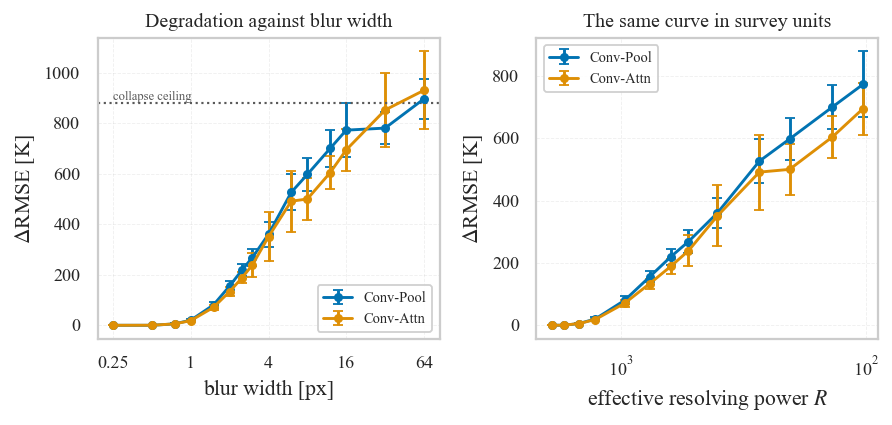

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.4))

sig_all = sorted(ov[ov.sweep.isin(['A', 'B'])].sigma.unique())
for m in MODELS:
    g = ov[ov.sweep.isin(['A', 'B'])]
    g = g[g.model == m].groupby('sigma')['d_rmse_K']
    axes[0].errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                     color=COLORS[m], marker='o', ms=4, lw=1.6, capsize=3, label=m)
axes[0].axhline(CEILING_MEAN, color='0.35', ls=':', lw=1.2)
axes[0].text(sig_all[0], CEILING_MEAN, 'collapse ceiling', fontsize=7, va='bottom',
             color='0.35')
axes[0].set_xscale('log')
axes[0].set_xticks([0.25, 1, 4, 16, 64])
axes[0].set_xticklabels(['0.25', '1', '4', '16', '64'])
axes[0].set_xlabel('blur width [px]')
axes[0].set_ylabel(r'$\Delta$RMSE [K]')
axes[0].set_title('Degradation against blur width', fontsize=11)
axes[0].legend(fontsize=8, framealpha=0.92)
axes[0].grid(True, ls='--', alpha=0.3, lw=0.5)

for m in MODELS:
    g = ov_A[ov_A.model == m].groupby('r_eff')['d_rmse_K']
    axes[1].errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                     color=COLORS[m], marker='o', ms=4, lw=1.6, capsize=3, label=m)
axes[1].set_xscale('log')
axes[1].invert_xaxis()
axes[1].set_xlabel('effective resolving power $R$')
axes[1].set_ylabel(r'$\Delta$RMSE [K]')
axes[1].set_title('The same curve in survey units', fontsize=11)
axes[1].legend(fontsize=8, framealpha=0.92)
axes[1].grid(True, ls='--', alpha=0.3, lw=0.5)

plt.tight_layout()
plt.show()

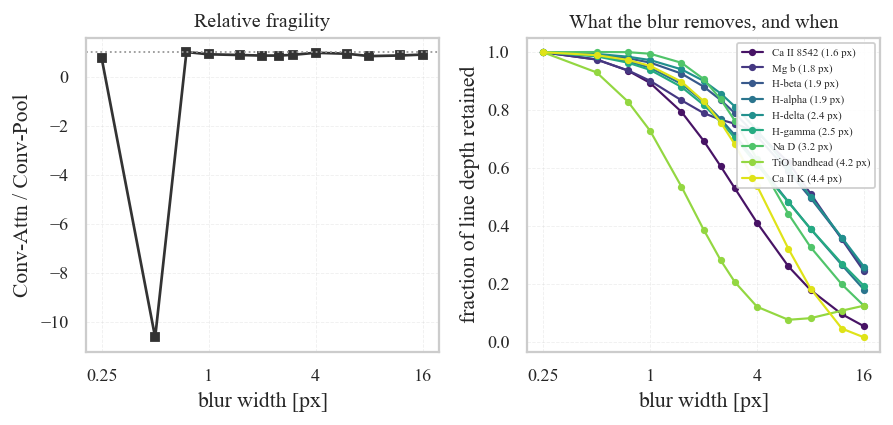

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.4))

ratio = []
for s in sorted(ov_A.sigma.unique()):
    p = ov_A[(ov_A.sigma == s) & (ov_A.model == 'Conv-Pool')]['d_rmse_K'].mean()
    a = ov_A[(ov_A.sigma == s) & (ov_A.model == 'Conv-Attn')]['d_rmse_K'].mean()
    ratio.append(a / p if p != 0 else np.nan)
axes[0].plot(sorted(ov_A.sigma.unique()), ratio, color='0.2', marker='s', ms=4, lw=1.5)
axes[0].axhline(1.0, color='0.6', lw=1.0, ls=':')
axes[0].set_xscale('log')
axes[0].set_xticks([0.25, 1, 4, 16])
axes[0].set_xticklabels(['0.25', '1', '4', '16'])
axes[0].set_xlabel('blur width [px]')
axes[0].set_ylabel('Conv-Attn / Conv-Pool')
axes[0].set_title('Relative fragility', fontsize=11)
axes[0].grid(True, ls='--', alpha=0.3, lw=0.5)

cmap = plt.get_cmap('viridis')
lines_sorted = list(widths_sorted.index)
for name, cl in zip(lines_sorted, cmap(np.linspace(0.05, 0.95, len(lines_sorted)))):
    sub = lineprof[lineprof.line == name].sort_values('sigma')
    axes[1].plot(sub['sigma'], sub['depth_retained'], marker='o', ms=3, lw=1.2,
                 color=cl, label=f'{name} ({widths_sorted[name]:.1f} px)')
axes[1].set_xscale('log')
axes[1].set_xticks([0.25, 1, 4, 16])
axes[1].set_xticklabels(['0.25', '1', '4', '16'])
axes[1].set_xlabel('blur width [px]')
axes[1].set_ylabel('fraction of line depth retained')
axes[1].set_title('What the blur removes, and when', fontsize=11)
axes[1].legend(fontsize=6, framealpha=0.92, loc='upper right')
axes[1].grid(True, ls='--', alpha=0.3, lw=0.5)

plt.tight_layout()
plt.show()

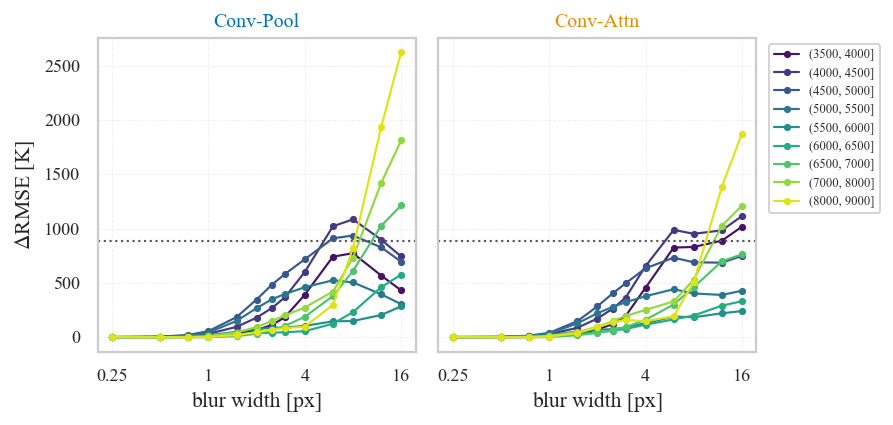

In [19]:
fig, axes = plt.subplots(1, len(MODELS), figsize=(W_DOUBLE, 3.4), sharey=True)
cmap = plt.get_cmap('viridis')
colors_reg = cmap(np.linspace(0.05, 0.95, len(REG_LABELS)))

sub = deg[(deg.sweep == 'A') & (deg.regime != 'all')]
for ax, m in zip(axes, MODELS):
    for lab, cl in zip(REG_LABELS, colors_reg):
        g = sub[(sub.model == m) & (sub.regime == lab)].groupby('sigma')['d_rmse_K'].mean()
        ax.plot(g.index, g.values, marker='o', ms=3, lw=1.2, color=cl, label=lab)
    ax.axhline(CEILING_MEAN, color='0.35', ls=':', lw=1.2)
    ax.set_xscale('log')
    ax.set_xticks([0.25, 1, 4, 16])
    ax.set_xticklabels(['0.25', '1', '4', '16'])
    ax.set_xlabel('blur width [px]')
    ax.set_title(m, color=COLORS[m], fontsize=11)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)
axes[0].set_ylabel(r'$\Delta$RMSE [K]')
axes[-1].legend(fontsize=7, framealpha=0.92, loc='upper left', bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.show()

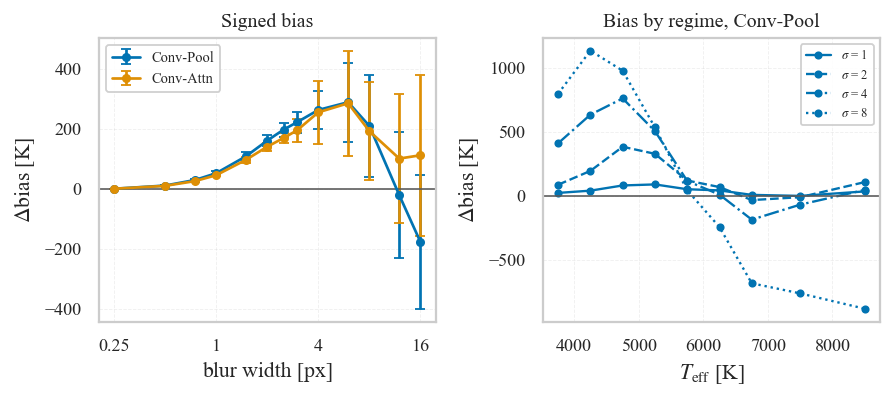

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.2))

for m in MODELS:
    g = ov_A[ov_A.model == m].groupby('sigma')['d_bias_K']
    axes[0].errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                     color=COLORS[m], marker='o', ms=4, lw=1.5, capsize=3, label=m)
axes[0].axhline(0, color='0.35', lw=0.9)
axes[0].set_xscale('log')
axes[0].set_xticks([0.25, 1, 4, 16])
axes[0].set_xticklabels(['0.25', '1', '4', '16'])
axes[0].set_xlabel('blur width [px]')
axes[0].set_ylabel(r'$\Delta$bias [K]')
axes[0].set_title('Signed bias', fontsize=11)
axes[0].legend(fontsize=8, framealpha=0.92)
axes[0].grid(True, ls='--', alpha=0.3, lw=0.5)

centres = [(REG_EDGES[i] + REG_EDGES[i + 1]) / 2 for i in range(len(REG_LABELS))]
for s, ls in zip([1.0, 2.0, 4.0, 8.0], ['-', '--', '-.', ':']):
    subs = deg[(deg.sigma == s) & (deg.regime != 'all') &
               (deg.model == 'Conv-Pool')]
    if len(subs) == 0:
        continue
    v = subs.pivot_table(index='regime', values='d_bias_K',
                         aggfunc='mean').reindex(REG_LABELS)['d_bias_K'].values
    axes[1].plot(centres, v, ls=ls, marker='o', ms=3.5, lw=1.3,
                 color=COLORS['Conv-Pool'], label=fr'$\sigma$ = {s:g}')
axes[1].axhline(0, color='0.35', lw=0.9)
axes[1].set_xlabel(r'$T_{\mathrm{eff}}$ [K]')
axes[1].set_ylabel(r'$\Delta$bias [K]')
axes[1].set_title('Bias by regime, Conv-Pool', fontsize=11)
axes[1].legend(fontsize=7, framealpha=0.92)
axes[1].grid(True, ls='--', alpha=0.3, lw=0.5)

plt.tight_layout()
plt.show()

## 5.4.9 Export

All dictionaries are built with explicit loops rather than comprehensions containing `DataFrame.query`, and the exported summary is checked against the tables above.

In [21]:
def level_summary(df, keys, key_name, value='d_rmse_K'):
    out = {}
    for m in MODELS:
        per = {}
        for k in keys:
            v = df[(df['model'] == m) & (df[key_name] == k)][value]
            per[str(k)] = [float(v.mean()), float(v.std())]
        out[m] = per
    return out


keys_A = [float(s) for s in SIGMA_LEVELS]
keys_B = [float(s) for s in SIGMA_CONTINUUM]
keys_C = [float(s) for s in SIGMA_NO_RENORM]

meta = {
    'step': '5.4',
    'attack': ATTACK,
    'description': 'Gaussian convolution of fixed pixel width, replicated edges, '
                   'median renormalisation applied as in Step 2',
    'attack_seed': ATTACK_SEED,
    'n_test': int(N_TEST),
    'seeds': SEEDS,
    'models': MODELS,
    'eval_batch_size': BATCH_SIZE,
    'catastrophic_threshold_K': CATASTROPHIC_K,
    'collapse_rmse_K': COLLAPSE_RMSE,
    'collapse_ceiling_d_rmse_K': CEILING,
    'clean_rmse_K': CLEAN_RMSE,
    'kernel_truncate_sigma': KERNEL_TRUNCATE,
    'r_instrument': R_INSTRUMENT,
    'km_s_per_pixel': KMS_PER_PIXEL,
    'sweep_A': {
        'sigma_px': keys_A,
        'r_eff': [round(r_effective(s), 1) for s in SIGMA_LEVELS],
        'd_rmse_K': level_summary(ov_A, keys_A, 'sigma'),
        'd_bias_K': level_summary(ov_A, keys_A, 'sigma', value='d_bias_K')},
    'sweep_B': {
        'sigma_px': keys_B,
        'r_eff': [round(r_effective(s), 1) for s in SIGMA_CONTINUUM],
        'd_rmse_K': level_summary(ov_B, keys_B, 'sigma')},
    'sweep_C': {
        'sigma_px': keys_C,
        'renormalisation': 'withheld',
        'd_rmse_K': level_summary(ov_c, keys_C, 'sigma')},
    'grid': GRID,
}
with open(os.path.join(RESULTS_DIR, 'step54_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

print('Written to results/:')
for fn in sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith('step54')):
    p = os.path.join(RESULTS_DIR, fn)
    if os.path.isfile(p):
        print(f'  {fn:40s} {os.path.getsize(p) / 1024:7.1f} KB')
tot = sum(os.path.getsize(os.path.join(STEP54_DIR, f))
          for f in os.listdir(STEP54_DIR)) / 1024 ** 2
print(f'  step54/  (per-spectrum predictions, every configuration)  {tot:.1f} MB')

for m in MODELS:
    a = meta['sweep_A']['d_rmse_K'][m][str(float(SIGMA_LEVELS[-1]))][0]
    b = float(ov_A[(ov_A.sigma == float(SIGMA_LEVELS[-1])) &
                   (ov_A.model == m)]['d_rmse_K'].mean())
    assert abs(a - b) < 1e-9, f'sweep A summary disagrees with the table for {m}'
    a = meta['sweep_B']['d_rmse_K'][m][str(float(SIGMA_CONTINUUM[-1]))][0]
    b = float(ov_B[(ov_B.sigma == float(SIGMA_CONTINUUM[-1])) &
                   (ov_B.model == m)]['d_rmse_K'].mean())
    assert abs(a - b) < 1e-9, f'sweep B summary disagrees with the table for {m}'
print()
print('Exported summaries verified against the in-notebook tables.')

Written to results/:
  step54_degradation.csv                     527.5 KB
  step54_degradation_norenorm.csv            105.7 KB
  step54_line_morphology.csv                   8.1 KB
  step54_line_widths_by_regime.csv             1.8 KB
  step54_meta.json                             7.4 KB
  step54_paired_tests.csv                      1.3 KB
  step54_plateau.csv                           0.5 KB
  step54_renorm_control.csv                    0.7 KB
  step54/  (per-spectrum predictions, every configuration)  11.4 MB

Exported summaries verified against the in-notebook tables.
